# Short-List Promising Models & Fine-Tune the System

Short-list checklist:
1. Train a bunch of quick models w/ default params
2. Compare them (CV mean + std)
3. Most important features <mark>TODO</mark>
4. What kinds of errors they make <mark>TODO</mark>
5. Any quick feature changes? (actually do them in Preparation) <mark>TODO</mark>
6. Pick top 3 - ideally ones that make different mistakes <mark>TODO</mark>

### Imports

In [1]:
%load_ext autoreload
%autoreload 2

import json
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             fbeta_score, make_scorer, precision_score, recall_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from custom_transformers import *

from sklearn import set_config
set_config(transform_output="pandas")

### Load data + preprocessor

In [2]:
TARGET_COL = "is_diseased"

train_set = pd.read_parquet("train_set.parquet")
X = train_set.drop(columns=TARGET_COL)
y = train_set[TARGET_COL].copy()
groups = train_set["Unique Squirrel ID"]   # same squirrel stays in one fold

with open("preprocessor.pkl", "rb") as f:
    preprocessor = pickle.load(f)

X_prepared = preprocessor.transform(X)
X_prepared.shape

(2418, 50)

In [3]:
# grouped + stratified folds, same idea as our train/test split
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# F2 = recall counts more than precision
f2 = make_scorer(fbeta_score, beta=2)
SCORING = {"f2": f2, "recall": "recall", "precision": "precision", "avg_precision": "average_precision"}
MAIN_METRIC = "f2"

RANDOM_STATE = 42

## Short-List Models

In [4]:
# default params on purpose (quick and dirty)
base_models = {
    "logreg": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "rf": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "hgb": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "svc": SVC(random_state=RANDOM_STATE),
    "knn": KNeighborsClassifier(),
    "nb": GaussianNB(),
    "mlp": MLPClassifier(max_iter=1000, random_state=RANDOM_STATE),
}

rows = []
for name, model in base_models.items():
    scores = cross_validate(model, X_prepared, y, groups=groups, cv=cv, scoring=SCORING)
    row = {"model": name}
    for metric in SCORING:
        row[metric] = scores[f"test_{metric}"].mean()
        row[f"{metric}_std"] = scores[f"test_{metric}"].std()
    rows.append(row)

shortlist_results = pd.DataFrame(rows).set_index("model").sort_values(MAIN_METRIC, ascending=False)
shortlist_results.round(3)

,f2,f2_std,recall,recall_std,precision,precision_std,avg_precision,avg_precision_std
model,,,,,,,,
nb,0.534,0.137,0.656,0.193,0.341,0.081,0.438,0.067
logreg,0.486,0.071,0.459,0.076,0.653,0.056,0.579,0.047
hgb,0.438,0.051,0.413,0.053,0.589,0.039,0.552,0.049
mlp,0.434,0.066,0.423,0.066,0.488,0.070,0.472,0.051
rf,0.430,0.050,0.400,0.050,0.622,0.041,0.535,0.040
tree,0.403,0.030,0.409,0.030,0.383,0.043,0.232,0.023
svc,0.373,0.049,0.333,0.048,0.733,0.035,0.579,0.044
knn,0.187,0.066,0.159,0.058,0.690,0.107,0.299,0.050


- thoughts on the scores / std <mark>TODO</mark>
- note: default models ignore that only ~12.5% are sick - class_weight gets tuned below

### Errors

In [5]:
# our top 3 picks - change this list if we want different ones
SHORTLIST = list(shortlist_results.index[:3])
SHORTLIST

['nb', 'logreg', 'hgb']

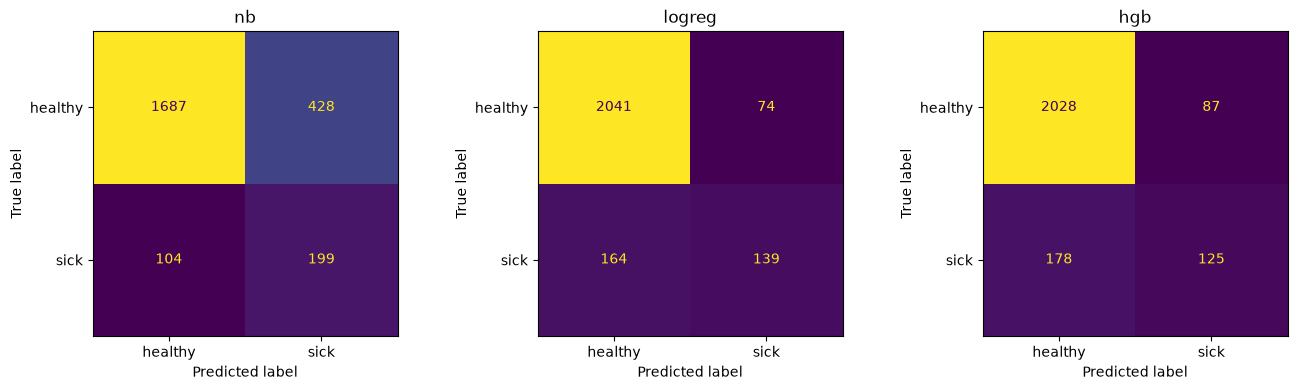

In [6]:
# out-of-fold predictions so every row is predicted by a model that didn't train on it
oof_preds = {
    name: cross_val_predict(base_models[name], X_prepared, y, groups=groups, cv=cv)
    for name in SHORTLIST
}

fig, axes = plt.subplots(1, len(SHORTLIST), figsize=(4.5 * len(SHORTLIST), 4))
for ax, name in zip(np.atleast_1d(axes), SHORTLIST):
    ConfusionMatrixDisplay.from_predictions(y, oof_preds[name], display_labels=["healthy", "sick"],
                                            colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [7]:
# do they miss the same sick squirrels? (low overlap = good for an ensemble)
missed = {name: set(np.where((y.values == 1) & (pred == 0))[0]) for name, pred in oof_preds.items()}
overlap = pd.DataFrame(
    [[len(missed[a] & missed[b]) for b in SHORTLIST] for a in SHORTLIST],
    index=SHORTLIST, columns=SHORTLIST,
)
print("sick squirrels missed (diagonal) and missed by both (off-diagonal):")
overlap

sick squirrels missed (diagonal) and missed by both (off-diagonal):


,nb,logreg,hgb
nb,104,93,90
logreg,93,164,147
hgb,90,147,178


- what kinds of mistakes? do the models miss different squirrels? <mark>TODO</mark>

### Important Features

In [8]:
# permutation importance: how much F2 drops when a feature gets shuffled
# (on training data, so just a rough look)
importances = {}
for name in SHORTLIST:
    model = clone(base_models[name]).fit(X_prepared, y)
    result = permutation_importance(model, X_prepared, y, scoring=f2, n_repeats=5,
                                    random_state=RANDOM_STATE, n_jobs=-1)
    importances[name] = pd.Series(result.importances_mean, index=X_prepared.columns)

importance_table = pd.DataFrame(importances)
importance_table.loc[importance_table.mean(axis=1).sort_values(ascending=False).index].head(20).round(4)

,nb,logreg,hgb
categorical__Primary Fur Color_Gray,0.1781,0.4034,0.5551
categorical__Primary Fur Color_Cinnamon,0.1972,0.1917,0.0023
categorical__Primary Fur Color_Black,0.1010,0.1459,0.0000
weather__shift_temp_c,0.0071,0.0281,0.2100
xy__X,-0.0043,0.0639,0.1526
counts__Hectare Squirrel Number,0.0005,0.0058,0.0890
counts__Number of Squirrels,0.0035,0.0054,0.0804
activity__Running,0.0007,0.0197,0.0683
xy__Y,-0.0053,-0.0112,0.0975
interaction__Runs from,0.0013,0.0299,0.0394


- top features - match what we saw in exploration? <mark>TODO</mark>
- anything useless we should drop in Preparation? <mark>TODO</mark>

# Fine-Tune the System

Fine-tune checklist:
1. Tune each shortlisted model w/ CV - 10+ hyperparameters, some preprocessing + some model <mark>TODO</mark>
2. Try an ensemble <mark>TODO</mark>
3. Check the final model on the test set (only once!) <mark>TODO</mark>

In [9]:
N_ITER = 30   # random combos per search
N_JOBS = 4    # each worker loads spaCy, so don't go too high

# original (unfitted) pieces of our preprocessor, by name
pre_parts = {name: part for name, part, cols in preprocessor.transformers}
activity_anchors = list(pre_parts["activity_text"].concepts)
interaction_anchors = list(pre_parts["interaction_text"].concepts)

# preprocessing hyperparameters shared by every search
PREP_PARAMS = {
    "preprocessor__activity_text__concepts": [
        activity_anchors,
        [a for a in activity_anchors if a != "running"],       # overlap w/ "runs away"?
    ],
    "preprocessor__interaction_text__concepts": [
        interaction_anchors,
        [a for a in interaction_anchors if a != "looking at me"],
    ],
    "preprocessor__interaction__merge_none_into_indifferent": [True, False],
    "preprocessor__vocal__any_flag_name": [None, "any_vocalization"],
    "preprocessor__counts__impute__strategy": ["median", "mean"],
    "preprocessor__height__impute__add_indicator": [True, False],
    "preprocessor__xy": [pre_parts["xy"], "drop"],             # need X/Y if we have hectare?
    "preprocessor__hectare": [pre_parts["hectare"], "drop"],
    "preprocessor__weather": [pre_parts["weather"], "drop"],
}

# 5:1 = missing a sick squirrel costs ~5x a false alarm
CLASS_WEIGHTS = [None, "balanced", {0: 1, 1: 5}]

In [10]:
# model + search space for each candidate (only the SHORTLIST ones get run)
MODEL_SPACES = {
    "logreg": (LogisticRegression(solver="liblinear", max_iter=5000, random_state=RANDOM_STATE), {
        "model__C": loguniform(1e-3, 1e2),
        "model__l1_ratio": [0.0, 1.0],   # 0 = L2, 1 = L1 (replaces penalty in newer sklearn)
        "model__class_weight": CLASS_WEIGHTS,
        "model__fit_intercept": [True, False],
    }),
    "tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        "model__max_depth": [3, 5, 8, 12, None],
        "model__min_samples_split": randint(2, 40),
        "model__min_samples_leaf": randint(1, 30),
        "model__criterion": ["gini", "entropy"],
        "model__max_features": [None, "sqrt", 0.5],
        "model__class_weight": CLASS_WEIGHTS,
    }),
    "rf": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), {
        "model__n_estimators": randint(100, 600),
        "model__max_depth": [4, 8, 12, 20, None],
        "model__min_samples_split": randint(2, 30),
        "model__min_samples_leaf": randint(1, 20),
        "model__max_features": ["sqrt", "log2", 0.3, 0.5],
        "model__bootstrap": [True, False],
        "model__class_weight": CLASS_WEIGHTS + ["balanced_subsample"],
    }),
    "hgb": (HistGradientBoostingClassifier(random_state=RANDOM_STATE), {
        "model__learning_rate": loguniform(0.01, 0.3),
        "model__max_iter": randint(50, 400),
        "model__max_leaf_nodes": randint(8, 64),
        "model__min_samples_leaf": randint(5, 60),
        "model__l2_regularization": loguniform(1e-4, 10),
        "model__class_weight": CLASS_WEIGHTS,
    }),
    "svc": (SVC(random_state=RANDOM_STATE), {
        "model__C": loguniform(1e-2, 1e2),
        "model__gamma": loguniform(1e-4, 1e0),
        "model__kernel": ["rbf", "poly", "sigmoid"],
        "model__degree": [2, 3],
        "model__class_weight": CLASS_WEIGHTS,
    }),
    "knn": (KNeighborsClassifier(), {
        "model__n_neighbors": randint(1, 40),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    }),
    "nb": (GaussianNB(), {
        "model__var_smoothing": loguniform(1e-12, 1e-2),
    }),
    "mlp": (MLPClassifier(max_iter=1000, early_stopping=True, random_state=RANDOM_STATE), {
        "model__hidden_layer_sizes": [(50,), (100,), (100, 50), (64, 32, 16)],
        "model__alpha": loguniform(1e-5, 1e-1),
        "model__learning_rate_init": loguniform(1e-4, 1e-2),
        "model__activation": ["relu", "tanh"],
    }),
}


def make_search(model, model_params):
    """Full pipeline (preprocessor + model) so preprocessing params get tuned too."""
    pipe = Pipeline([("preprocessor", clone(preprocessor)), ("model", model)])
    params = {**PREP_PARAMS, **model_params}
    search = RandomizedSearchCV(pipe, params, n_iter=N_ITER, scoring=SCORING, refit=MAIN_METRIC,
                                cv=cv, n_jobs=N_JOBS, random_state=RANDOM_STATE)
    return search, len(params)

In [11]:
searches = {}
for name in SHORTLIST:
    model, model_params = MODEL_SPACES[name]
    search, n_params = make_search(model, model_params)
    print(f"{name}: tuning {n_params} hyperparameters")
    search.fit(X, y, groups=groups)
    searches[name] = search

nb: tuning 10 hyperparameters


logreg: tuning 13 hyperparameters


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

... (8 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


hgb: tuning 15 hyperparameters


In [12]:
def summarize(searches):
    """Best CV scores + params for each search."""
    rows = []
    for name, s in searches.items():
        i = s.best_index_
        row = {"model": name}
        for metric in SCORING:
            row[metric] = s.cv_results_[f"mean_test_{metric}"][i]
        row[f"{MAIN_METRIC}_std"] = s.cv_results_[f"std_test_{MAIN_METRIC}"][i]
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").sort_values(MAIN_METRIC, ascending=False)

display(summarize(searches).round(3))
for name, s in searches.items():
    print(f"\n{name} best params:")
    for k, v in s.best_params_.items():
        print(f"  {k}: {v}")

,f2,recall,precision,avg_precision,f2_std
model,,,,,
hgb,0.655,0.729,0.467,0.547,0.049
logreg,0.648,0.706,0.487,0.421,0.055
nb,0.615,0.703,0.412,0.499,0.032



nb best params:
  model__var_smoothing: 0.005001479828856931
  preprocessor__activity_text__concepts: ['sitting still', 'chasing', 'digging burying nut', 'playing']
  preprocessor__counts__impute__strategy: mean
  preprocessor__hectare: drop
  preprocessor__height__impute__add_indicator: False
  preprocessor__interaction__merge_none_into_indifferent: False
  preprocessor__interaction_text__concepts: ['approaches people', 'curious', 'runs away', 'dog']
  preprocessor__vocal__any_flag_name: None
  preprocessor__weather: Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('scale', StandardScaler())])
  preprocessor__xy: drop

logreg best params:
  model__C: 0.01379354235277247
  model__class_weight: balanced
  model__fit_intercept: True
  model__l1_ratio: 1.0
  preprocessor__activity_text__concepts: ['sitting still', 'chasing', 'digging burying nut', 'running', 'playing']
  preprocessor__counts__impute__strategy: median
  preprocessor__hectare: Pipeline(steps=[

- which preprocessing choices won? (anchors, dropping xy/hectare/weather, etc.) <mark>TODO</mark>
- did class_weight matter? <mark>TODO</mark>

### Ensemble

In [13]:
# voting ensemble of our 3 tuned models, sharing one preprocessor
def tuned_model(name):
    model = clone(searches[name].best_estimator_.named_steps["model"])
    if isinstance(model, SVC):
        model.set_params(probability=True)   # needed for soft voting
    return model

# 1 extra knob per model inside the ensemble
ENSEMBLE_EXTRA = {
    "logreg": {"C": loguniform(1e-3, 1e2)},
    "tree": {"max_depth": [3, 5, 8, None]},
    "rf": {"max_depth": [4, 8, 12, None]},
    "hgb": {"learning_rate": loguniform(0.01, 0.3)},
    "svc": {"C": loguniform(1e-2, 1e2)},
    "knn": {"n_neighbors": randint(1, 40)},
    "nb": {"var_smoothing": loguniform(1e-12, 1e-2)},
    "mlp": {"alpha": loguniform(1e-5, 1e-1)},
}

voting = VotingClassifier([(name, tuned_model(name)) for name in SHORTLIST], voting="soft")

ensemble_params = {
    # soft only - hard voting has no probabilities for average_precision
    "model__weights": [None] + [tuple(3 if j == i else 1 for j in range(len(SHORTLIST))) for i in range(len(SHORTLIST))],
}
for name in SHORTLIST:
    for k, v in ENSEMBLE_EXTRA[name].items():
        ensemble_params[f"model__{name}__{k}"] = v

ensemble_search, n_params = make_search(voting, ensemble_params)
print(f"ensemble: tuning {n_params} hyperparameters")
ensemble_search.fit(X, y, groups=groups)
searches["voting"] = ensemble_search

summarize(searches).round(3)

ensemble: tuning 13 hyperparameters


,f2,recall,precision,avg_precision,f2_std
model,,,,,
hgb,0.655,0.729,0.467,0.547,0.049
logreg,0.648,0.706,0.487,0.421,0.055
voting,0.639,0.706,0.465,0.524,0.037
nb,0.615,0.703,0.412,0.499,0.032


- does the ensemble actually beat the best single model? worth the extra complexity? <mark>TODO</mark>

## Final Model

In [14]:
# best CV score wins; best_estimator_ is already refit on the full training set
best_name = summarize(searches).index[0]
final_model = searches[best_name].best_estimator_
print("final model:", best_name)

with open("model.pkl", "wb") as f:
    pickle.dump(final_model, f)

# reload check
with open("model.pkl", "rb") as f:
    reloaded = pickle.load(f)
assert (reloaded.predict(X) == final_model.predict(X)).all()
print("model.pkl reloads correctly")

final model: hgb


model.pkl reloads correctly


In [15]:
# save CV scores for the Presentation charts
comparison = {
    "default": shortlist_results[["f2", "recall", "precision"]].round(4).to_dict(orient="index"),
    "tuned": summarize(searches)[["f2", "recall", "precision", "f2_std"]].round(4).to_dict(orient="index"),
    "final_model": best_name,
}
with open("model_comparison.json", "w") as f:
    json.dump(comparison, f, indent=2)


### Test Set

F2:        0.607
recall:    0.671
precision: 0.440

              precision    recall  f1-score   support

     healthy       0.95      0.88      0.91       529
        sick       0.44      0.67      0.53        76

    accuracy                           0.85       605
   macro avg       0.69      0.77      0.72       605
weighted avg       0.88      0.85      0.86       605



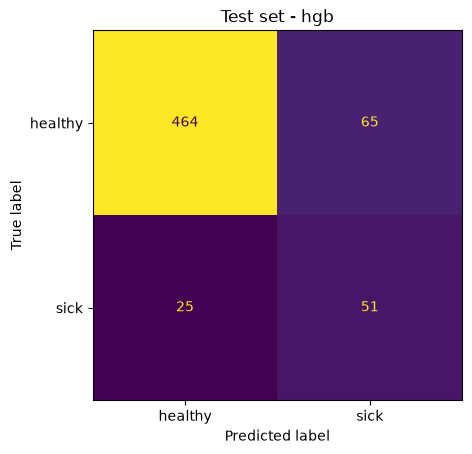

In [16]:
# only run this once we're done tuning!
test_set = pd.read_parquet("test_set.parquet")
X_test = test_set.drop(columns=TARGET_COL)
y_test = test_set[TARGET_COL].copy()

test_preds = final_model.predict(X_test)
print(f"F2:        {fbeta_score(y_test, test_preds, beta=2):.3f}")
print(f"recall:    {recall_score(y_test, test_preds):.3f}")
print(f"precision: {precision_score(y_test, test_preds):.3f}")
print()
print(classification_report(y_test, test_preds, target_names=["healthy", "sick"]))
ConfusionMatrixDisplay.from_predictions(y_test, test_preds, display_labels=["healthy", "sick"], colorbar=False)
plt.title(f"Test set - {best_name}")
plt.show()

- test vs CV scores - close or did we overfit? <mark>TODO</mark>
- good enough for the client's recall goal? <mark>TODO</mark>